# Point-cloud normals

`estimate_normals(points, k=16)` gives every point of a scan a normal from the points alone: a plane is fitted to each point and its `k` nearest neighbours, and the sides are made consistent by propagating along a minimum spanning tree of the neighbour graph (Hoppe et al. 1992), then turned outward. The result is `point_data["normals"]`, the normal columns of a PCD or XYZ file. See `doc/point_normals.md`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

# PyVista is not needed here: the clouds are drawn as matplotlib scatter and
# quiver plots, which render without GL.

## A closed scan: consistent and outward

Points on and near the skin of a lumpy body. A plane fit alone gives each normal an arbitrary side (`orientation="none"` makes the largest component positive, which is deterministic but flips across the body); the consistent orientation turns every normal outward.

{'num_degenerate': 0, 'num_components': 1}
outward: 51% with orientation="none", 100% consistent


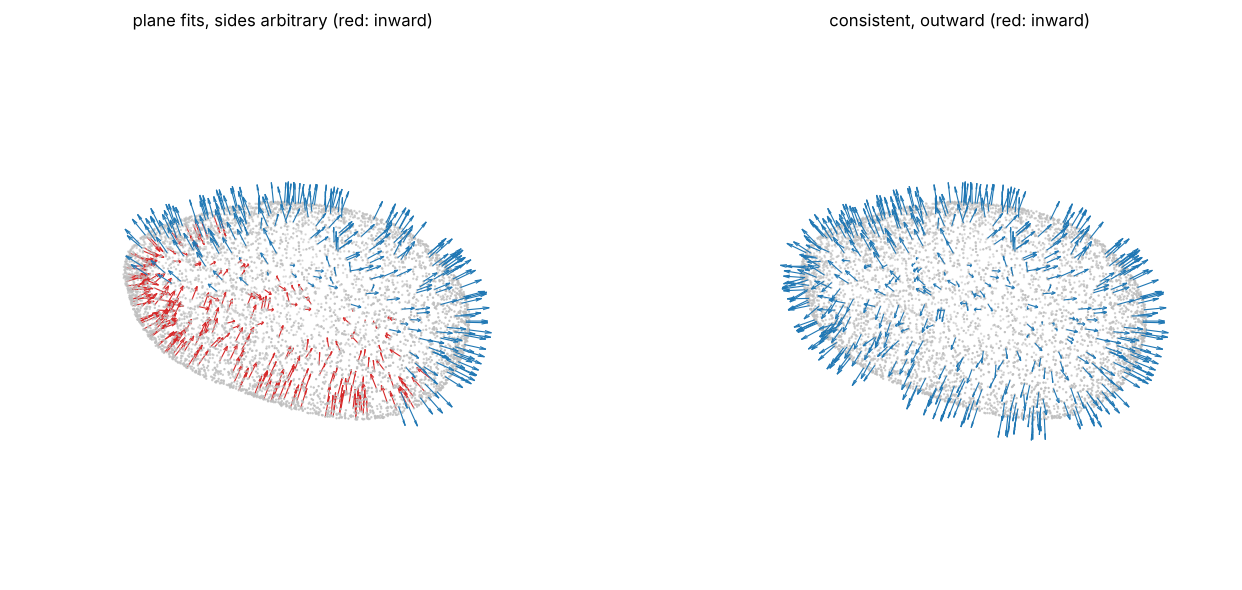

In [2]:
rng = np.random.default_rng(3)
d = rng.normal(size=(6000, 3))
d /= np.linalg.norm(d, axis=1)[:, None]
radius = 1.0 + 0.2 * np.sin(3 * d[:, 0]) * np.cos(2 * d[:, 1])
cloud = d * radius[:, None] * [1.5, 1.0, 0.8] + rng.normal(scale=0.004, size=(6000, 3))

raw = mp.estimate_normals(cloud, orientation='none').point_data['normals']
out, report = mp.estimate_normals(cloud, k=16, return_report=True)
n = out.point_data['normals']
print(report)
outward = lambda m: np.mean(np.einsum('ij,ij->i', m, cloud - cloud.mean(axis=0)) > 0)
print(f'outward: {outward(raw):.0%} with orientation="none", {outward(n):.0%} consistent')

pick = rng.choice(len(cloud), 500, replace=False)
fig = plt.figure(figsize=(14, 6))
for i, (normals, title) in enumerate(((raw, 'plane fits, sides arbitrary'), (n, 'consistent, outward'))):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    p, v = cloud[pick], normals[pick]
    out_side = np.einsum('ij,ij->i', v, p) > 0
    ax.scatter(*cloud.T, s=0.5, c='0.75')
    for mask, colour in ((out_side, 'tab:blue'), (~out_side, 'tab:red')):
        ax.quiver(*p[mask].T, *v[mask].T, length=0.18, color=colour, linewidth=0.8)
    ax.set_box_aspect((1.5, 1.0, 0.8)); ax.set_axis_off()
    ax.set_title(f'{title} (red: inward)')
plt.tight_layout()
plt.show()

## Surface variation finds the edges

`record_variation=True` adds `normals:variation`, `λ₀ / (λ₀ + λ₁ + λ₂)` of each neighbourhood: 0 where the points lie on a plane, larger at edges and corners, where the fitted plane straddles two faces.

{'num_degenerate': 0, 'num_components': 1} variation: median 0.00e+00, max 0.184


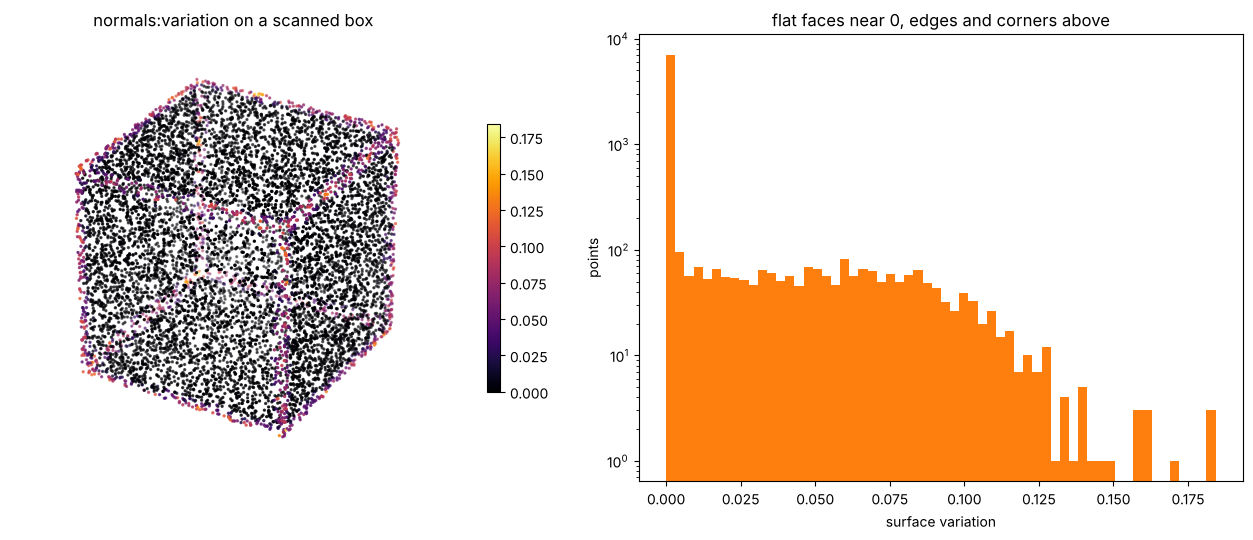

In [3]:
faces = []
for axis in range(3):
    for side in (0.0, 1.0):
        uv = rng.random((1500, 2))
        p = np.insert(uv, axis, side, axis=1)
        faces.append(p)
box = np.vstack(faces)
boxed, rep = mp.estimate_normals(box, k=20, record_variation=True, return_report=True)
var = boxed.point_data['normals:variation']
print(rep, f'variation: median {np.median(var):.2e}, max {var.max():.3f}')

fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
sc = ax.scatter(*box.T, s=2, c=var, cmap='inferno')
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.set_title('normals:variation on a scanned box')
plt.colorbar(sc, ax=ax, shrink=0.6)
ax = fig.add_subplot(1, 2, 2)
ax.hist(var, bins=60, color='tab:orange'); ax.set_yscale('log')
ax.set_xlabel('surface variation'); ax.set_ylabel('points'); ax.set_title('flat faces near 0, edges and corners above')
plt.tight_layout()
plt.show()

## A single scan from one side: towards the viewpoint

A terrain scanned from above is an open sheet; `orientation="viewpoint"` points every normal towards the scanner. The normals then go to a PCD file as its `normal_x normal_y normal_z` columns.

every normal faces the scanner: True; least n_z 0.893
# .PCD v0.7 - Point Cloud Data file format
# Written by meshio++ v18.0.0
# Note [dtype]: float64 coordinates written as float32 (point_dtype='float32')
VERSION 0.7


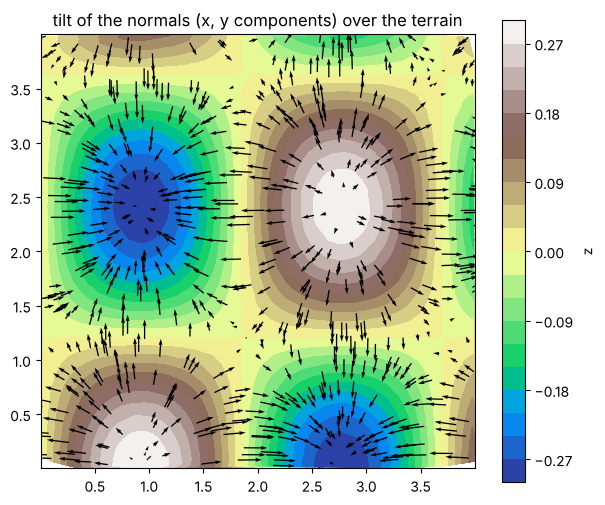

In [4]:
xy = rng.random((3000, 2)) * 4.0
z = 0.3 * np.sin(1.7 * xy[:, 0]) * np.cos(1.3 * xy[:, 1])
sheet = np.column_stack([xy, z])
seen = mp.estimate_normals(sheet, k=12, orientation='viewpoint', viewpoint=(2.0, 2.0, 10.0))
nz = seen.point_data['normals'][:, 2]
print(f'every normal faces the scanner: {bool(np.all(nz > 0))}; least n_z {nz.min():.3f}')

path = os.path.join(tempfile.mkdtemp(), 'sheet.pcd')
mp.write(path, mp.Mesh(sheet, [], point_data={'normals': seen.point_data['normals']}))
with open(path, 'rb') as f:
    print(b''.join(f.readlines()[:4]).decode().strip())

fig, ax = plt.subplots(figsize=(7, 6))
sel = rng.choice(len(sheet), 700, replace=False)
tc = ax.tricontourf(xy[:, 0], xy[:, 1], z, levels=20, cmap='terrain')
ax.quiver(xy[sel, 0], xy[sel, 1], seen.point_data['normals'][sel, 0], seen.point_data['normals'][sel, 1],
          scale=8, width=0.003)
ax.set_aspect('equal'); ax.set_title('tilt of the normals (x, y components) over the terrain')
plt.colorbar(tc, ax=ax, label='z')
plt.show()

## In a pipeline, and on the command line

The step is `EstimateNormals`; the verb `point-normals` in both CLIs.

In [5]:
_, rep = mp.apply_operations(mp.Mesh(cloud, []), [{"Op": "EstimateNormals", "K": 16}])
print(rep['steps'][0])
print('meshioplusplus point-normals scan.ply scan.pcd --k 24 --json')

{'op': 'EstimateNormals', 'NumDegenerate': 0.0, 'NumComponents': 1.0}
meshioplusplus point-normals scan.ply scan.pcd --k 24 --json
